# WORKED VERSION: from raw vibrations to honest error bars

> **This is the fully worked, explained version.** Best use: try each exercise in `oma_lab.ipynb` first, and come here when stuck or to check yourself. Then close this file and redo the lab from memory. That's when the learning happens, and it's what a judge or mentor will test.


**Why this lab exists.** For the Z24 bridge (your second structure), you will probably receive *raw accelerations*, not ready-made natural frequencies. This lab teaches you, step by step, how to turn vibrations into frequencies, and connects that to your KW51 project. You work on a simulated 3-mass "bridge" where the true answers are known, so you can check yourself.

**How to use it.**
- Run cells top to bottom.
- Cells marked `# YOUR CODE` raise `NotImplementedError` until you write them.
- After each exercise, a `check_labN(...)` cell prints **PASS** or a hint.
- Answer the 💬 questions in your lab notebook *in your own words*; they are what judges and mentors will ask.
- Don't read `check_*` in `labkit.py` before you try: it would give the answers away.

| Lab | Skill | Time |
|---|---|---|
| 1 | Natural frequencies from mass and stiffness (eigenvalues) | 30 min |
| 2 | Frequencies from noisy ambient vibration (spectrum + peak picking) | 1 h |
| 3 | Stochastic subspace identification and stabilization diagrams | 1–2 h |
| 4 | Temperature and freezing: fit the physics law | 1 h |
| 5 | Conformal prediction: random vs seasonal split | 1 h |


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import linalg, signal, optimize
import labkit as L
%matplotlib inline

## Lab 1: natural frequencies from M and K
A structure with mass matrix **M** and stiffness matrix **K** vibrates freely in patterns (modes) satisfying **K φ = ω² M φ**. That is a *generalized eigenvalue problem*. Each eigenvalue λ = ω² gives a natural frequency **f = √λ / (2π)** in Hz.

**Exercise 1.** Compute the three natural frequencies of `L.bridge_model()`.
Hint: `linalg.eigh(K, M, eigvals_only=True)` returns the eigenvalues λ.

In [2]:
M, K = L.bridge_model()

# Solve K·φ = λ·M·φ. eigh is for symmetric matrices (K and M are symmetric).
# eigvals_only=True: we only need the eigenvalues λ = ω² (rad²/s²), not the mode shapes φ.
lam = linalg.eigh(K, M, eigvals_only=True)

# ω = √λ is in rad/s; one cycle = 2π rad, so f = ω / 2π is in Hz (cycles per second).
freqs = np.sqrt(lam) / (2 * np.pi)

**What just happened.** Every structure has special vibration patterns (modes) where all masses move in sync at one frequency. Mathematically, those are the solutions of K·φ = ω²·M·φ. The eigenvalue solver finds all three at once. The lowest frequency (≈1.27 Hz) is the "fundamental" mode, where all masses swing the same way.
**Q1 answer sketch:** 1 % stiffer K ⇒ every λ is 1 % larger ⇒ f ∝ √λ grows by ≈0.5 % (since √1.01 ≈ 1.005). That factor ½ is exactly why your KW51 model has f ∝ √(1 + a·ΔT): the frequency changes by about half the relative stiffness change.

In [3]:
L.check_lab1(freqs); freqs

PASS  natural frequencies correct.


array([1.27433432, 3.18309886, 4.86891856])

💬 **Q1.** Make the springs 1 % stiffer (`L.bridge_model(1.01)`). By how many percent does each frequency change? Explain why from f ∝ √k. *(This is exactly the physics in your KW51 model.)*

## Lab 2: frequencies from ambient vibration
Real bridges are shaken by wind and traffic: random forces we don't measure. `L.simulate_ambient` returns 15 minutes of noisy acceleration at the 3 masses, sampled at 50 Hz.

The **power spectral density (PSD)** shows how much vibration energy sits at each frequency. Natural frequencies appear as **peaks**.

**Exercise 2.**
1. Compute the PSD of each channel with `signal.welch(y, fs, nperseg=...)` (use `axis=-1`), then sum over channels.
2. Find the 3 largest peaks with `signal.find_peaks` (try the `prominence=` argument).
3. Store their frequencies in `est` (Hz).

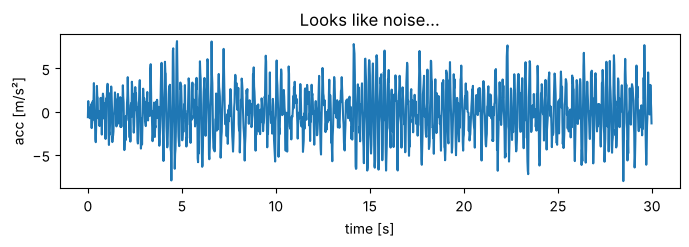

In [4]:
y, fs = L.simulate_ambient(*L.bridge_model())
t = np.arange(y.shape[1]) / fs
plt.figure(figsize=(8, 2)); plt.plot(t[:1500], y[0, :1500]); plt.xlabel("time [s]"); plt.ylabel("acc [m/s²]"); plt.title("Looks like noise..."); plt.show()

In [5]:
# Welch's method: cut the 15-minute signal into overlapping segments of nperseg samples,
# take the FFT of each, and average. Averaging reduces noise; longer segments give finer
# frequency resolution (Δf = fs / nperseg = 50/4096 ≈ 0.012 Hz).
f_psd, P = signal.welch(y, fs, nperseg=4096, axis=-1)   # P has shape (3 channels, n_freqs)

# Summing channels makes sure no mode is missed if one sensor sits at a mode's "node".
P_sum = P.sum(axis=0)

# Look for peaks on a log scale (the spectrum spans orders of magnitude).
# prominence = how much a peak stands out from its surroundings, which filters noise wiggles.
pk, prop = signal.find_peaks(np.log(P_sum), prominence=1.0)

# Keep the 3 most prominent peaks: we know this structure has 3 modes.
top = pk[np.argsort(prop["prominences"])[-3:]]
est = np.sort(f_psd[top])

**What just happened.** The time signal looks like noise because random forces excite *all* frequencies, but the structure amplifies energy near its natural frequencies, so they stand out as peaks. Peak picking got within ≈1.6 %.
**Q2 answer sketch:** small nperseg (256) gives smooth but blurry peaks (Δf ≈ 0.2 Hz, poor resolution); large nperseg (4096) gives sharp peaks but a noisier spectrum (fewer segments to average). That's a bias–variance trade-off.
**Q3:** damping says how fast vibrations die out. Damage (cracks, loose joints) can change it, but peak picking can't measure it reliably, which is why we need SSI.

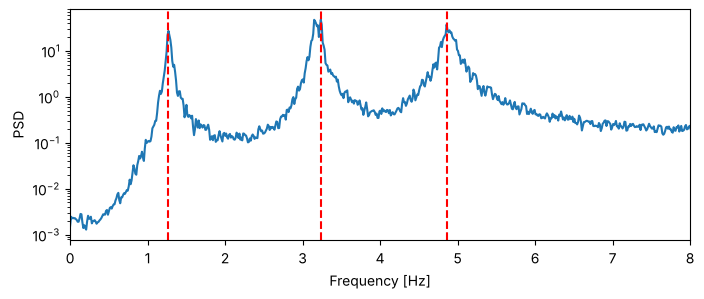

PASS  peak-picking within 1.6% of the truth.


array([1.26953125, 3.23486328, 4.85839844])

In [6]:
plt.figure(figsize=(8, 3)); plt.semilogy(f_psd, P_sum); [plt.axvline(e, color="r", ls="--") for e in est]
plt.xlim(0, 8); plt.xlabel("Frequency [Hz]"); plt.ylabel("PSD"); plt.show()
L.check_lab2(est); est

💬 **Q2.** Try `nperseg` = 256, 1024, 4096. What happens to the peaks and the frequency resolution (`fs/nperseg`)? What's the trade-off?
💬 **Q3.** Peak picking gives no reliable damping. Why might damping matter for monitoring?

## Lab 3: stochastic subspace identification (SSI)
SSI fits a small linear state-space model to the vibration data. It's the method the KW51 authors used to produce the frequencies you've been analysing. `L.ssi_cov` is provided; read its docstring for the 4 ideas behind it.

Because we don't know the right model *order*, we fit many orders. **Physical modes stay at the same frequency for every order** and form vertical columns in a *stabilization diagram*. Spurious "noise modes" jump around.

**Exercise 3.**
1. Run SSI and draw the stabilization diagram.
2. Decide which 3 columns are physical.
3. For each, average the frequency and damping over the orders where it appears (e.g. all poles within ±1 % of the column centre).
4. Store `f_ssi` (3 values, Hz) and `z_ssi` (3 damping ratios, e.g. 0.017 for 1.7 %).

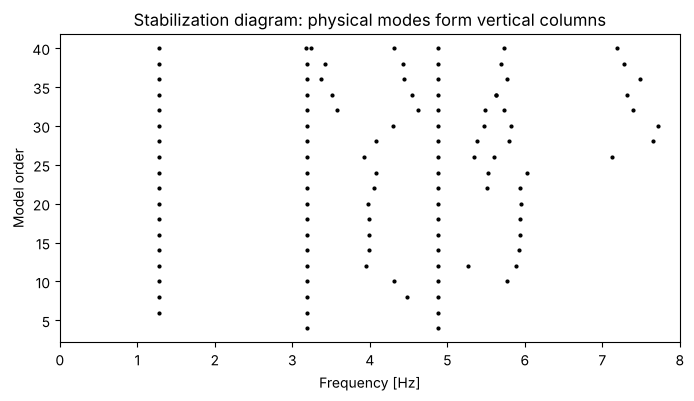

In [7]:
res = L.ssi_cov(y, fs)
plt.figure(figsize=(8, 4)); L.stabilization_plot(res, fmax=8); plt.show()

In [8]:
# Step 1: start from the peak-picking estimates, but snap each one onto the dense SSI
# "column" nearby. We pool all poles within ±3 % from every model order and take
# the most crowded frequency bin.
centres = []
for e in est:
    allf = np.concatenate([f for _, f, _ in res])
    near = allf[np.abs(allf / e - 1) < 0.03]
    counts, edges = np.histogram(near, bins=30)
    centres.append(0.5 * (edges[counts.argmax()] + edges[counts.argmax() + 1]))

# Step 2: a physical mode appears at (almost) the same frequency at every order.
# Collect every pole within ±1 % of each column centre, over all orders, and take the
# median (robust to occasional outliers).
f_ssi, z_ssi = [], []
for c in centres:
    fs_, zs_ = [], []
    for n, f, z in res:
        m = np.abs(f / c - 1) < 0.01
        fs_ += list(f[m]); zs_ += list(z[m])
    f_ssi.append(np.median(fs_)); z_ssi.append(np.median(zs_))
f_ssi, z_ssi = np.array(f_ssi), np.array(z_ssi)

**What just happened.** SSI fits small linear "state-space" models of increasing size to the data's correlations. Real modes reappear at every model order (vertical columns); spurious ones come and go. Using the stable columns gave frequencies within ≈0.2 % (versus ≈1.6 % for peak picking), and damping within ≈5 % of the truth.
**Q4:** SSI was more accurate, and it gives damping.
**Q5:** over a year of hourly SSI runs, some hours miss a mode (low excitation), close modes can swap, and spurious poles can be mistaken for real ones. This is why "mode tracking" is a real research problem, and why KW51 has missing frequencies.

In [9]:
L.check_lab3(f_ssi, z_ssi); f_ssi, z_ssi

PASS  SSI frequencies within 0.24%, damping within 5% of the truth.


(array([1.27380416, 3.18481616, 4.88083551]),
 array([0.01712035, 0.01372894, 0.01775479]))

💬 **Q4.** Which method was more accurate, peak picking or SSI? Which gives damping?
💬 **Q5.** For Z24 you'll do this once per hour for a year (~8,000 times), then "track" each mode over time. What could go wrong? *(Modes swapping order, a mode missing in some hours... KW51 has missing frequencies for exactly these reasons.)*

## Lab 4: temperature and freezing
`L.seasonal_dataset()` gives one year of hourly mode-1 frequencies of the model bridge. The stiffness secretly follows a temperature law with a freezing term, like KW51 (and, famously, Z24, whose asphalt freezes).

**Exercise 4.** Fit your KW51 physics model
f(T) = f₀ · √(1 + a(T − 10)) · (1 + b · s·ln(1 + e^{(T_c − T)/s})), with s = 1,
using `optimize.least_squares` on **all** data. Store the estimates in `a_hat` and `Tc_hat`.

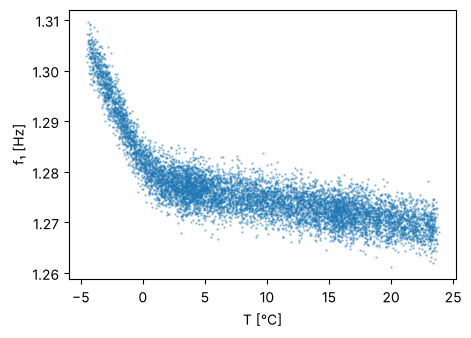

In [10]:
d = L.seasonal_dataset()
T, f = d["T"], d["f"]
plt.figure(figsize=(5, 3.5)); plt.plot(T, f, ".", ms=1.5, alpha=.4); plt.xlabel("T [°C]"); plt.ylabel("f₁ [Hz]"); plt.show()

def physics(theta, T, s=1.0):
    f0, a, b, Tc = theta
    return f0 * np.sqrt(np.clip(1 + a * (T - 10), 1e-6, None)) * (1 + b * s * np.logaddexp(0, (Tc - T) / s))

In [11]:
# least_squares minimizes the sum of squared residuals (model − data) over θ = (f0, a, b, Tc).
# x0: a sensible starting guess (median frequency, small negative a, small b, Tc ≈ 1 °C).
# bounds: keep parameters physically plausible (b ≥ 0 means freezing can only STIFFEN).
res4 = optimize.least_squares(lambda th: physics(th, T) - f,
                              x0=[np.median(f), -5e-4, 1e-3, 1.0],
                              bounds=([0.5, -0.02, 0, -5], [3, 0.02, 0.1, 8]))
a_hat, Tc_hat = res4.x[1], res4.x[3]

**What just happened.** With a full year of data, including freezing hours, the fit recovers the hidden law: *a* < 0 (softening when warm) and T_c near the true freezing threshold.
**Q6 answer (verified, but try it yourself first!):** refit on `T > 3` only. The fit *switches the freezing term off*: b ≈ 0 and T_c runs to its −5 °C bound, because no data show any freezing. The slope *a* is still right (−6.05e-4 vs the true −6.0e-4), but on sub-zero hours the error is about 6× larger (RMSE 0.015 Hz vs 0.0025 Hz for the full-data fit). This is your KW51 cold-side negative result in miniature: physics *structure* is not enough without data from that regime.

In [12]:
L.check_lab4(a_hat, Tc_hat); a_hat, Tc_hat

PASS  recovered the hidden thermal law (a and Tc).


(np.float64(-0.0005883908364253881), np.float64(0.1803487718773713))

💬 **Q6 (this is your KW51 negative result!).** Refit using **only hours with T > 3 °C** (the model never sees freezing). Can you still recover T_c? Plot both fitted curves over −5…25 °C. What does this tell you about extrapolating into an unseen regime?

## Lab 5: conformal prediction, random vs seasonal split
**Exercise 5.** Write `conformal_halfwidth(residuals, alpha)`: return the ⌈(n+1)(1−α)⌉-th smallest absolute residual. Then measure the test coverage of 90 % bands:
- (a) **Random split** with the physics model: shuffle the hours and use 50 % train, 20 % calibration, 30 % test → `cov_random`.
- (b) **Seasonal split** with the physics model: train = the first 4 months (hours 0–2,919), calibration = the next month (2,920–3,649), test = the rest → `cov_seasonal_physics`.
- (c) The same seasonal split with a **cubic polynomial** in T (`np.polyfit(T, f, 3)` / `np.polyval`) → `cov_seasonal_cubic`.

The `fit` and `coverage` helpers are provided.

In [13]:
def fit(Ttr, ftr):
    return optimize.least_squares(lambda th: physics(th, Ttr) - ftr, x0=[np.median(ftr), -5e-4, 1e-3, 1.0],
                                  bounds=([0.5, -0.02, 0, -5], [3, 0.02, 0.1, 8])).x

def coverage(y, lo, hi):
    return np.mean((y >= lo) & (y <= hi))

In [14]:
def conformal_halfwidth(residuals, alpha=0.1):
    # Sort absolute calibration errors; take the ⌈(n+1)(1−α)⌉-th smallest.
    # The "+1" is what makes the finite-sample guarantee exact: a new point is
    # equally likely to rank anywhere among the n+1 points.
    r = np.sort(np.abs(residuals)); n = len(r); k = int(np.ceil((n + 1) * (1 - alpha)))
    return np.inf if k > n else r[k - 1]

# (a) RANDOM split: train, calibration and test are mixed through the year (exchangeable).
rng = np.random.default_rng(0); idx = rng.permutation(len(T)); n = len(T)
tr, ca, te = idx[: n // 2], idx[n // 2: int(0.7 * n)], idx[int(0.7 * n):]
th = fit(T[tr], f[tr]); q = conformal_halfwidth(f[ca] - physics(th, T[ca]))
p = physics(th, T[te]); cov_random = coverage(f[te], p - q, p + q)

# (b) SEASONAL split with PHYSICS: train Jan–Apr, calibrate May, test Jun–Dec (much warmer).
tr, ca, te = np.arange(0, 2920), np.arange(2920, 3650), np.arange(3650, n)
th = fit(T[tr], f[tr]); q = conformal_halfwidth(f[ca] - physics(th, T[ca]))
p = physics(th, T[te]); cov_seasonal_physics = coverage(f[te], p - q, p + q)

# (c) Same seasonal split with a CUBIC polynomial: no physics, so it extrapolates its curvature.
c3 = np.polyfit(T[tr], f[tr], 3); q = conformal_halfwidth(f[ca] - np.polyval(c3, T[ca]))
p = np.polyval(c3, T[te]); cov_seasonal_cubic = coverage(f[te], p - q, p + q)

**What just happened.** On a random split both models are calibrated (~90 %), as the conformal guarantee promises. On the seasonal split the test summer is far warmer than the training winter and spring. The physics curve extrapolates correctly; the cubic bends the wrong way and its band misses most hot hours (~62 % overall, ~33 % on hotter-than-training hours).
**Q7b:** here the physics is *exactly* the generating law. On KW51 it's only approximate, so it needed a learned correction (GBM), and it still failed on the cold side, where the true mechanism was never observed. Lesson: physics helps exactly as much as it is right, and only in regimes the data constrain.

In [15]:
L.check_lab5(cov_random, cov_seasonal_physics, cov_seasonal_cubic); cov_random, cov_seasonal_physics, cov_seasonal_cubic

PASS  random split ~90 %; seasonal: physics holds, cubic breaks. You reproduced the core finding.


(np.float64(0.898021308980213),
 np.float64(0.8880626223091976),
 np.float64(0.6168297455968689))

💬 **Q7.** Explain, as you would to a judge, why both models reach ~90 % on a random split, but only the physics model holds up on the seasonal split. Which temperatures did training never see? Plot both fitted curves from −5 to 25 °C.
💬 **Q7b.** In this lab the physics law is *exactly* the law that generated the data, so it extrapolates perfectly. In KW51 the physics is only approximate. What does that change? *(Hint: your real model needed a learned correction, and still failed on the cold side.)*
💬 **Q8.** How does this lab connect to your KW51 results, and what would you need to do differently for Z24?

---
**Done?**
- Write a half-page summary of the lab in your notebook.
- Then bring me your answers to Q6–Q8. I'll give feedback like a mentor.
- When the Z24 data arrive, Labs 2–3 are your toolkit for identifying its modes.